###Step 1 – Install the libraries

In [1]:
!pip -q install datasets gradio

###Step 2 – Import libraries and configure the environment

In [2]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
import matplotlib.pyplot as plt
import gradio as gr

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

Device: cuda


###Step 3 – Load the TinyStories dataset

In [3]:
# Load 10,000 stories

dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:10000]"
)

# Split into training and validation datasets

dataset = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

train_text = "\n".join(dataset["train"]["text"])
val_text = "\n".join(dataset["test"]["text"])

print("Training stories:", len(dataset["train"]))
print("Validation stories:", len(dataset["test"]))

print("\nSample training text:")
print(train_text[:500])

Training stories: 9000
Validation stories: 1000

Sample training text:
Once upon a time, there was a little girl named Lily. She loved to play in her backyard. One day, she went outside to play, but it was very quiet. She looked around and saw that all the birds had flown away. 

Suddenly, she heard a loud noise. It was her neighbor, Mr. Brown, who was cutting down a tree. Lily didn't like that because she loved the trees in her backyard. She went to Mr. Brown and said, "Please stop cutting the tree. I don't want it to go away." 

Mr. Brown said, "I'm sorry, Lily, 


###Step 4 – Convert text into numerical IDs

In [4]:
# Create character vocabulary

chars = sorted(set(train_text + val_text))

vocab_size = len(chars)

# Create character-to-number mapping

stoi = {ch: i for i, ch in enumerate(chars)}

# Create number-to-character mapping

itos = {i: ch for i, ch in enumerate(chars)}

# Encoding function

def encode(text):
    return [stoi[ch] for ch in text]

# Decoding function

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

# Convert training and validation text into tensors

train_data = torch.tensor(
    encode(train_text),
    dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text),
    dtype=torch.long
)

print("Vocabulary size:", vocab_size)

print("Encoded sample:")
print(encode("Once upon a time")[:20])

print("\nDecoded sample:")
print(decode(encode("Once upon a time")))

Vocabulary size: 92
Encoded sample:
[38, 63, 52, 54, 1, 70, 65, 64, 63, 1, 50, 1, 69, 58, 62, 54]

Decoded sample:
Once upon a time


###Step 5 – Define the Transformer model

In [5]:
class TinyTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        block_size,
        embedding_dim=128,
        num_heads=4,
        num_layers=4,
        feedforward_dim=512
    ):

        super().__init__()

        # Character embedding

        self.token_emb = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Positional embedding

        self.pos_emb = nn.Embedding(
            block_size,
            embedding_dim
        )

        # Transformer encoder layer

        layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=0.1,
            batch_first=True,
            activation="gelu"
        )

        # Multiple Transformer layers

        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=num_layers
        )

        # Output layer

        self.lm_head = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, idx):

        B, T = idx.shape

        # Generate positional indices

        positions = torch.arange(
            T,
            device=idx.device
        )

        # Token embeddings + positional embeddings

        x = (
            self.token_emb(idx)
            + self.pos_emb(positions)
        )

        # Causal mask: prevent future information leakage

        mask = torch.triu(
            torch.ones(
                T,
                T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Transformer processing

        x = self.blocks(
            x,
            mask=mask
        )

        # Predict next character probabilities

        logits = self.lm_head(x)

        return logits

###Step 6 – Initialize the model

In [6]:
# Model configuration

block_size = 256
batch_size = 32

embedding_dim = 128
num_heads = 4
num_layers = 4
feedforward_dim = 512

# Initialize model

model = TinyTransformer(
    vocab_size=vocab_size,
    block_size=block_size,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    feedforward_dim=feedforward_dim
).to(device)

# Calculate parameter count

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Model initialized successfully!")
print("Number of parameters:", total_parameters)
print("Model device:", device)

Model initialized successfully!
Number of parameters: 849500
Model device: cuda


###Step 7 – Prepare training batches

In [7]:
def get_batch(split_name):

    source = train_data if split_name == "train" else val_data

    # Random starting positions

    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    # Input sequences

    x = torch.stack([
        source[i:i + block_size]
        for i in starts
    ])

    # Target sequences (shifted by one character)

    y = torch.stack([
        source[i + 1:i + block_size + 1]
        for i in starts
    ])

    return x.to(device), y.to(device)

In [8]:
x, y = get_batch("train")

print("Input shape:", x.shape)
print("Target shape:", y.shape)

print("Input sample:")
print(decode(x[0].tolist()))

print("\nTarget sample:")
print(decode(y[0].tolist()))

Input shape: torch.Size([32, 256])
Target shape: torch.Size([32, 256])
Input sample:
 valuable lesson and decided never to trust anyone again!
Once upon a time there was a little girl who was so very careful. One day she went outside to play and she found a caterpillar! She was so excited!

The girl carefully put the caterpillar in her poc

Target sample:
valuable lesson and decided never to trust anyone again!
Once upon a time there was a little girl who was so very careful. One day she went outside to play and she found a caterpillar! She was so excited!

The girl carefully put the caterpillar in her pock


###Step 8 – Define the evaluation function

In [9]:
@torch.no_grad()
def evaluate(split_name, num_batches=10):

    model.eval()

    losses = []

    for _ in range(num_batches):

        x, y = get_batch(split_name)

        logits = model(x)

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()

    return sum(losses) / len(losses)

###Step 9 – Train the Transformer

In [10]:
# Optimizer

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

# Store losses

train_history = []
val_history = []

# Training configuration

epochs = 20
steps_per_epoch = 500

# Training loop

for epoch in range(epochs):

    model.train()

    total_loss = 0.0

    for step in range(steps_per_epoch):

        # Get batch

        x, y = get_batch("train")

        # Forward pass

        logits = model(x)

        # Calculate loss

        loss = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        # Reset gradients

        optimizer.zero_grad()

        # Backpropagation

        loss.backward()

        # Update model parameters

        optimizer.step()

        total_loss += loss.item()

    # Average training loss

    train_loss = total_loss / steps_per_epoch

    # Validation loss

    val_loss = evaluate(
        "val",
        num_batches=20
    )

    # Store results

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

Epoch 01/20 | Train Loss: 2.2508 | Validation Loss: 1.7639
Epoch 02/20 | Train Loss: 1.6550 | Validation Loss: 1.3693
Epoch 03/20 | Train Loss: 1.4121 | Validation Loss: 1.2132
Epoch 04/20 | Train Loss: 1.2969 | Validation Loss: 1.1460
Epoch 05/20 | Train Loss: 1.2289 | Validation Loss: 1.0968
Epoch 06/20 | Train Loss: 1.1844 | Validation Loss: 1.0674
Epoch 07/20 | Train Loss: 1.1491 | Validation Loss: 1.0258
Epoch 08/20 | Train Loss: 1.1253 | Validation Loss: 0.9955
Epoch 09/20 | Train Loss: 1.1043 | Validation Loss: 1.0074
Epoch 10/20 | Train Loss: 1.0871 | Validation Loss: 0.9775
Epoch 11/20 | Train Loss: 1.0695 | Validation Loss: 0.9639
Epoch 12/20 | Train Loss: 1.0596 | Validation Loss: 0.9568
Epoch 13/20 | Train Loss: 1.0474 | Validation Loss: 0.9465
Epoch 14/20 | Train Loss: 1.0378 | Validation Loss: 0.9504
Epoch 15/20 | Train Loss: 1.0266 | Validation Loss: 0.9313
Epoch 16/20 | Train Loss: 1.0215 | Validation Loss: 0.9250
Epoch 17/20 | Train Loss: 1.0148 | Validation Loss: 0.91

###Step 10 – Plot the training and validation loss

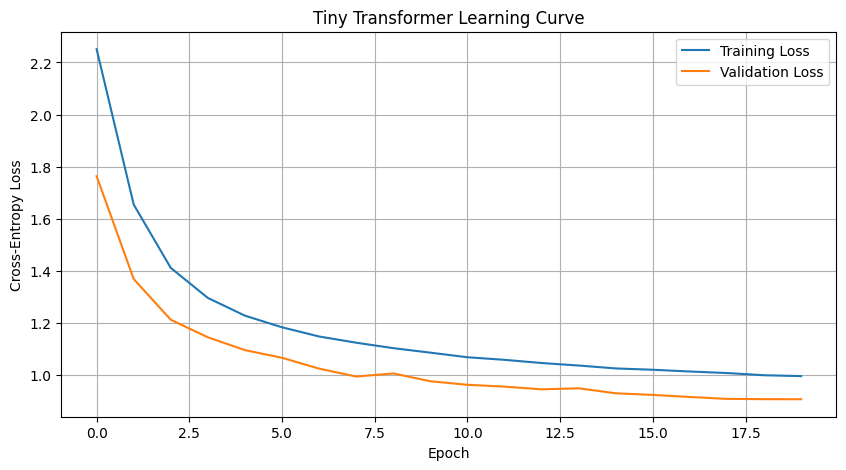

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    train_history,
    label="Training Loss"
)

plt.plot(
    val_history,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")

plt.title("Tiny Transformer Learning Curve")

plt.legend()

plt.grid(True)

plt.show()

###Step 11 – Calculate validation perplexity

In [12]:
# Calculate final validation loss

final_val_loss = evaluate(
    "val",
    num_batches=50
)

# Calculate perplexity

val_perplexity = math.exp(
    min(final_val_loss, 20)
)

print("Final Validation Loss:", round(final_val_loss, 4))

print("Final Validation Perplexity:", round(val_perplexity, 2))

Final Validation Loss: 0.902
Final Validation Perplexity: 2.46


###Step 12 – Generate text

In [13]:
@torch.no_grad()
def generate(
    prompt,
    max_new_chars=300,
    temperature=0.7
):

    model.eval()

    # Check unsupported characters

    unsupported = [
        ch for ch in prompt
        if ch not in stoi
    ]

    if unsupported:

        raise ValueError(
            f"Unsupported characters: {unsupported}"
        )

    # Encode prompt

    ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long
    ).to(device)

    # Generate characters

    for _ in range(max_new_chars):

        # Limit context

        idx_cond = ids[:, -block_size:]

        # Predict

        logits = model(idx_cond)

        # Select last character prediction

        logits = logits[:, -1, :]

        # Temperature adjustment

        logits = logits / max(temperature, 0.01)

        # Probability distribution

        probs = F.softmax(
            logits,
            dim=-1
        )

        # Sample next character

        next_id = torch.multinomial(
            probs,
            num_samples=1
        )

        # Append character

        ids = torch.cat(
            [ids, next_id],
            dim=1
        )

    # Decode

    generated_text = decode(
        ids[0].tolist()
    )

    # Return continuation only

    return generated_text[len(prompt):]

###Step 13 – Test the model before building the interface

In [14]:
test_prompts = [
    "Once upon a time",
    "There was a little girl",
    "One day, a little boy",
    "The little rabbit",
    "Once upon a time, there was"
]

for prompt in test_prompts:

    print("=" * 80)

    print("PROMPT:", prompt)

    print("\nGENERATED STORY:")

    print(
        generate(
            prompt,
            max_new_chars=200,
            temperature=0.7
        )
    )

    print()

PROMPT: Once upon a time

GENERATED STORY:
, there was a little girl named Lily. She loved to play with its friends. One day, she was very curious and found a friendly who lived in a big just who was very curious.

One day, Lily woke up and th

PROMPT: There was a little girl

GENERATED STORY:
 who loved to play with her toys and exploring that she couldn't wait to go.

One day, Lily took the other dress and the little boy and the boy was not like to be too friends. She started to drop back

PROMPT: One day, a little boy

GENERATED STORY:
 named Timmy. Timmy loved to play with his bird, and it was a little girl named Lily. She loved to impate the garden back in the water. One day, he decided to go back to the spider and the rope. They 

PROMPT: The little rabbit

GENERATED STORY:
 was happy. As she was because it was so happy to have their pretty and friends wrong. They were so happy and waved her toys about the volcano. Everyone cheered the car of the nat and thanked them for

PROMPT:

###Step 14 – Save the trained model

In [15]:
checkpoint = {

    "model_state_dict": model.state_dict(),

    "chars": chars,

    "vocab_size": vocab_size,

    "config": {

        "embedding_dim": embedding_dim,

        "num_heads": num_heads,

        "num_layers": num_layers,

        "block_size": block_size,

        "feedforward_dim": feedforward_dim

    },

    "train_history": train_history,

    "val_history": val_history

}

torch.save(
    checkpoint,
    "tiny_transformer_improved.pt"
)

print("Model saved successfully!")

Model saved successfully!


###Step 15 – Build the Gradio interface

In [16]:
def story_generator(message, history):

    if not message or not message.strip():

        return "Please enter a story beginning."

    # Validate characters

    unsupported = [
        ch for ch in message
        if ch not in stoi
    ]

    if unsupported:

        return (
            "Your prompt contains unsupported characters. "
            "Please try another prompt."
        )

    try:

        response = generate(
            message,
            max_new_chars=300,
            temperature=0.7
        )

        return response

    except Exception as e:

        return (
            f"Generation failed: "
            f"{type(e).__name__}: {e}"
        )


demo = gr.ChatInterface(

    fn=story_generator,

    title="✨ TinyStories Generator",

    description=(
        "Enter the beginning of a story. "
        "The Transformer will attempt to continue it."
    ),

    textbox=gr.Textbox(
        placeholder="Once upon a time...",
        label="Story beginning"
    )
)

demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://97e4155ed9626d7be1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://97e4155ed9626d7be1.gradio.live
